## Question 5

In [47]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
import torch

data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print("Dataset loaded")
print(torch.__version__)

Dataset loaded
2.14.1+cpu


In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
print("train:", X_train.shape, "| test:", X_test.shape)
print("fraction benign — train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

train: (455, 30) | test: (114, 30)
fraction benign — train: 0.626, test: 0.632


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Data scaled")

Data scaled


### Helper function

In [50]:
import matplotlib.pyplot as plt

def plot_loss_curves(histories, title, log_scale=False):
    """Plot up to two training-loss curves. histories maps a label to a loss_history list."""
    colors = ["#2a78d6", "#eb6834"]
    fig, ax = plt.subplots(figsize=(7, 4))
    for (label, history), color in zip(histories.items(), colors):
        ax.plot(range(len(history)), history, color=color, linewidth=2, label=label)
    ax.axhline(np.log(2), color="gray", linewidth=1, linestyle="--", label="starting loss (log 2)")
    if log_scale:
        ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("training BCE loss" + (" (log scale)" if log_scale else ""))
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    plt.show()


def train_sgd(predict_fn, label, learning_rate=0.1, batch_size=32, epochs=200, seed=0):
    """Train weights w and bias b by minimizing BCE with mini-batch SGD, then plot the loss curve.
    predict_fn(X, w, b) must return probabilities. Returns w, b, loss_history."""
    torch.manual_seed(seed)

    w = torch.zeros(X_train_t.shape[1], requires_grad=True)
    b = torch.tensor(0.0, requires_grad=True)
    optimizer = torch.optim.SGD([w, b], lr=learning_rate)

    n = len(X_train_t)
    loss_history = []
    with torch.no_grad():
        loss_history.append(bce_loss(y_train_t, predict_fn(X_train_t, w, b)).item())

    for epoch in range(epochs):
        perm = torch.randperm(n)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            p = predict_fn(X_train_t[idx], w, b)
            loss = bce_loss(y_train_t[idx], p)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            loss_history.append(bce_loss(y_train_t, predict_fn(X_train_t, w, b)).item())

    plot_loss_curves({label: loss_history}, f"SGD training loss: {label}")
    return w, b, loss_history

### Baseline: Logistic Regression Model - sklearn's implementation (breast cancer dataset)

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

baseline = LogisticRegression()
baseline.fit(X_train_s, y_train)

baseline_pred = baseline.predict(X_test_s)
print("train accuracy:", baseline.score(X_train_s, y_train))
print("test accuracy: ", accuracy_score(y_test, baseline_pred))
print("solver iterations:", baseline.n_iter_)

pd.DataFrame(
    confusion_matrix(y_test, baseline_pred),
    index=["actual malignant", "actual benign"],
    columns=["predicted malignant", "predicted benign"],
)

train accuracy: 0.989010989010989
test accuracy:  0.9824561403508771
solver iterations: [17]


,predicted malignant,predicted benign
actual malignant,40,2
actual benign,0,72


### Logistic Regression Model using SGD (breast cancer dataset)

In [52]:
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)

print("X_train:", X_train_t.shape, X_train_t.dtype)
print("y_train:", y_train_t.shape, y_train_t.dtype)

X_train: torch.Size([455, 30]) torch.float32
y_train: torch.Size([455]) torch.float32


In [53]:
def predict(X, w, b):
    """f(x_i) = sigmoid(w^T x_i + b), computed for every row of X at once."""
    z = X @ w + b
    return torch.sigmoid(z)

def bce_loss(y, p, eps=1e-7):
    """Binary cross-entropy, averaged over observations."""
    p = torch.clamp(p, eps, 1 - eps)
    per_obs = -(y * torch.log(p) + (1 - y) * torch.log(1 - p))
    return per_obs.mean()

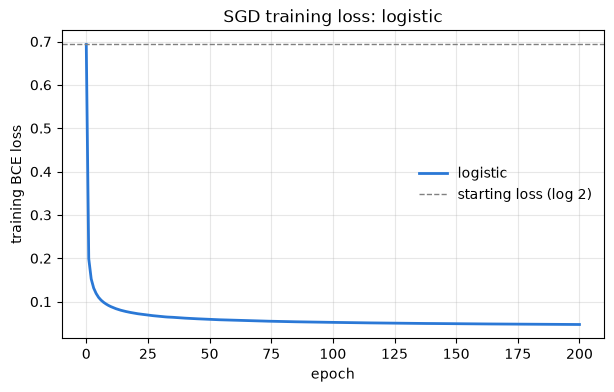

train loss after last epoch: 0.0473


In [54]:
w, b, loss_history = train_sgd(
    predict,
    "logistic",
    learning_rate=0.1,
    batch_size=32,
    epochs=200,
    seed=0,
)

print("train loss after last epoch:", round(loss_history[-1], 4))

In [55]:
with torch.no_grad():
    p_test = predict(X_test_t, w, b)
    p_train = predict(X_train_t, w, b)

sgd_pred = (p_test >= 0.5).int().numpy()
sgd_train_pred = (p_train >= 0.5).int().numpy()

print("SGD train accuracy:     ", accuracy_score(y_train, sgd_train_pred))
print("SGD test accuracy:      ", accuracy_score(y_test, sgd_pred))
print("baseline test accuracy: ", accuracy_score(y_test, baseline_pred))
print("SGD test BCE loss:      ", bce_loss(y_test_t, p_test).item())
print("test rows where SGD and baseline agree:", (sgd_pred == baseline_pred).mean())

pd.DataFrame(
    confusion_matrix(y_test, sgd_pred),
    index=["actual malignant", "actual benign"],
    columns=["predicted malignant", "predicted benign"],
)

SGD train accuracy:      0.9868131868131869
SGD test accuracy:       0.9824561403508771
baseline test accuracy:  0.9824561403508771
SGD test BCE loss:       0.08046574890613556
test rows where SGD and baseline agree: 1.0


,predicted malignant,predicted benign
actual malignant,40,2
actual benign,0,72


Overall, it has the same performance as the baseline!

In [45]:
weights = pd.DataFrame(
    {"SGD": w.detach().numpy(), "sklearn": baseline.coef_[0]},
    index=X.columns,
)
print("bias — SGD:", round(b.item(), 3), "| sklearn:", round(baseline.intercept_[0], 3))
print("correlation between the two weight vectors:",
      round(np.corrcoef(weights["SGD"], weights["sklearn"])[0, 1], 3))
print("largest |weight| — SGD:", round(weights["SGD"].abs().max(), 2),
      "| sklearn:", round(weights["sklearn"].abs().max(), 2))
weights.round(2)

bias — SGD: 0.387 | sklearn: 0.341
correlation between the two weight vectors: 0.994
largest |weight| — SGD: 1.49 | sklearn: 1.32


,SGD,sklearn
mean radius,-0.68,-0.54
mean texture,-0.59,-0.43
mean perimeter,-0.63,-0.49
mean area,-0.73,-0.57
mean smoothness,-0.21,-0.13
mean compactness,0.41,0.45
mean concavity,-0.85,-0.74
mean concave points,-1.05,-0.96
mean symmetry,0.09,0.11
mean fractal dimension,0.54,0.43


But it's slightly different still.

### Probit Regression Model using SGD (breast cancer dataset)

In [57]:
normal = torch.distributions.Normal(0.0, 1.0)

def predict_probit(X, w, b):
    """f(x_i) = Phi(w^T x_i + b), where Phi is the standard normal CDF."""
    z = X @ w + b
    return normal.cdf(z)

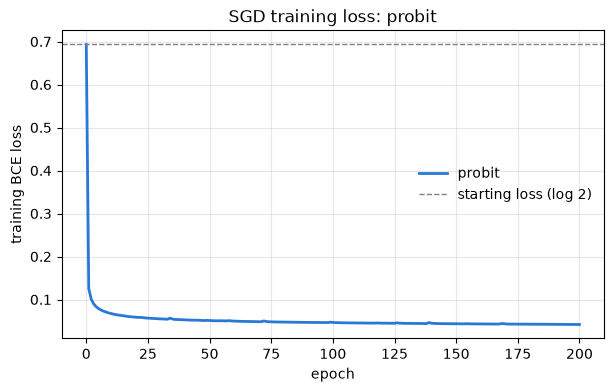

In [59]:
probit_w, probit_b, probit_loss_history = train_sgd(
    predict_probit,
    "probit",
    learning_rate=0.1,
    batch_size=32,
    epochs=200,
    seed=0,
)

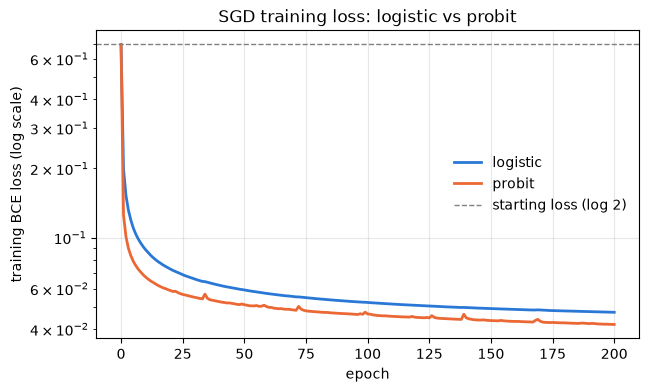

In [60]:
plot_loss_curves(
    {"logistic": loss_history, "probit": probit_loss_history},
    "SGD training loss: logistic vs probit",
    log_scale=True,
)

In [61]:
with torch.no_grad():
    probit_p_test = predict_probit(X_test_t, probit_w, probit_b)
    probit_p_train = predict_probit(X_train_t, probit_w, probit_b)

probit_pred = (probit_p_test >= 0.5).int().numpy()
probit_train_pred = (probit_p_train >= 0.5).int().numpy()

print("probit train accuracy:  ", accuracy_score(y_train, probit_train_pred))
print("probit test accuracy:   ", accuracy_score(y_test, probit_pred))
print("baseline test accuracy: ", accuracy_score(y_test, baseline_pred))
print("probit test BCE loss:   ", bce_loss(y_test_t, probit_p_test).item())
print("test rows where probit and baseline agree:", (probit_pred == baseline_pred).mean())

pd.DataFrame(
    confusion_matrix(y_test, probit_pred),
    index=["actual malignant", "actual benign"],
    columns=["predicted malignant", "predicted benign"],
)

probit train accuracy:   0.9912087912087912
probit test accuracy:    0.9824561403508771
baseline test accuracy:  0.9824561403508771
probit test BCE loss:    0.07998669892549515
test rows where probit and baseline agree: 1.0


,predicted malignant,predicted benign
actual malignant,40,2
actual benign,0,72


In [62]:
weights["probit SGD"] = probit_w.detach().numpy()
weights["logistic / probit"] = weights["SGD"] / weights["probit SGD"]

print("bias — probit SGD:", round(probit_b.item(), 3))
print("correlation, logistic SGD vs probit SGD:",
      round(np.corrcoef(weights["SGD"], weights["probit SGD"])[0, 1], 3))
print("median ratio logistic / probit:", round(weights["logistic / probit"].median(), 2))
weights.round(2)

bias — probit SGD: -0.118
correlation, logistic SGD vs probit SGD: 0.94
median ratio logistic / probit: 1.43


,SGD,sklearn,probit SGD,logistic / probit
mean radius,-0.68,-0.54,-0.27,2.52
mean texture,-0.59,-0.43,-0.21,2.79
mean perimeter,-0.63,-0.49,-0.21,2.97
mean area,-0.73,-0.57,-0.36,2.02
mean smoothness,-0.21,-0.13,-0.09,2.31
mean compactness,0.41,0.45,0.74,0.56
mean concavity,-0.85,-0.74,-0.57,1.50
mean concave points,-1.05,-0.96,-0.90,1.16
mean symmetry,0.09,0.11,0.31,0.28
mean fractal dimension,0.54,0.43,0.24,2.20


Again, same results as baseline and the logistic model, but here the weights are slightly more different.

### Baseline: Linear Regression Model - sklearn's implementation (ALE dataset)

In [63]:
ale = pd.read_csv("data/mcs_ds_edited_iter_shuffled.csv")
ale_features = ["anchor_ratio", "trans_range", "node_density", "iterations"]
ale_X = ale[ale_features]
ale_y = ale["ale"]

ale_X_train, ale_X_test, ale_y_train, ale_y_test = train_test_split(
    ale_X, ale_y, test_size=0.2, random_state=0
)
print("train:", ale_X_train.shape, "| test:", ale_X_test.shape)

train: (85, 4) | test: (22, 4)


In [65]:
ale_scaler = StandardScaler()
ale_X_train_s = ale_scaler.fit_transform(ale_X_train)
ale_X_test_s = ale_scaler.transform(ale_X_test)

In [66]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

ale_baseline = LinearRegression()
ale_baseline.fit(ale_X_train_s, ale_y_train)
ale_baseline_pred = ale_baseline.predict(ale_X_test_s)

print("baseline test MAE:        ", mean_absolute_error(ale_y_test, ale_baseline_pred))
print("predict-the-mean test MAE:", mean_absolute_error(ale_y_test, np.full(len(ale_y_test), ale_y_train.mean())))
print("weights:", ale_baseline.coef_.round(3), "| bias:", round(ale_baseline.intercept_, 3))

baseline test MAE:         0.1920717204588799
predict-the-mean test MAE: 0.32122581499197866
weights: [-0.054 -0.072 -0.293 -0.214] | bias: 1.018


### Linear Regression Model using SGD (ALE dataset)

In [68]:
ale_X_train_t = torch.tensor(ale_X_train_s, dtype=torch.float32)
ale_X_test_t = torch.tensor(ale_X_test_s, dtype=torch.float32)
ale_y_train_t = torch.tensor(ale_y_train.values, dtype=torch.float32)
ale_y_test_t = torch.tensor(ale_y_test.values, dtype=torch.float32)

print("X_train:", ale_X_train_t.shape, "| y_train:", ale_y_train_t.shape)

X_train: torch.Size([85, 4]) | y_train: torch.Size([85])


In [69]:
def predict_linear(X, w, b):
    """f(x_i) = w^T x_i + b, computed for every row of X at once."""
    return X @ w + b

def mse_loss(y, y_pred):
    """Squared error (y_i - f(x_i))^2, averaged over observations."""
    return ((y - y_pred) ** 2).mean()

In [74]:
def train_sgd_regression(predict_fn, label, loss_fn=mse_loss, learning_rate=0.01, batch_size=32, epochs=300, seed=0):
    """Train weights w and bias b by minimizing loss_fn on the ALE training data with
    mini-batch SGD, then plot the loss curve. Returns w, b, loss_history."""
    torch.manual_seed(seed)

    w = torch.zeros(ale_X_train_t.shape[1], requires_grad=True)
    b = torch.tensor(0.0, requires_grad=True)
    optimizer = torch.optim.SGD([w, b], lr=learning_rate)

    n = len(ale_X_train_t)
    loss_history = []
    with torch.no_grad():
        loss_history.append(loss_fn(ale_y_train_t, predict_fn(ale_X_train_t, w, b)).item())

    for epoch in range(epochs):
        perm = torch.randperm(n)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            p = predict_fn(ale_X_train_t[idx], w, b)
            loss = loss_fn(ale_y_train_t[idx], p)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            loss_history.append(loss_fn(ale_y_train_t, predict_fn(ale_X_train_t, w, b)).item())

    # Reference: the loss of always predicting the training mean
    mean_pred = ale_y_train_t.mean() * torch.ones_like(ale_y_train_t)
    mean_only_loss = loss_fn(ale_y_train_t, mean_pred).item()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(len(loss_history)), loss_history, color="#2a78d6", linewidth=2, label=label)
    ax.axhline(mean_only_loss, color="gray", linewidth=1, linestyle="--", label="predict-the-mean loss")
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("training loss (log scale)")
    ax.set_title(f"SGD training loss: {label}")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    plt.show()

    return w, b, loss_history

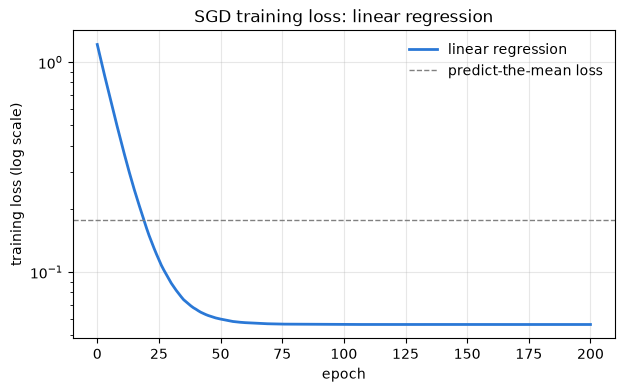

train MSE before training: 1.2135
train MSE after training:  0.05625


In [75]:
ale_w, ale_b, ale_loss_history = train_sgd_regression(
    predict_linear,
    "linear regression",
    learning_rate=0.01,
    batch_size=32,
    epochs=200,
    seed=0,
)

print("train MSE before training:", round(ale_loss_history[0], 4))
print("train MSE after training: ", round(ale_loss_history[-1], 5))

In [76]:
with torch.no_grad():
    ale_sgd_pred = predict_linear(ale_X_test_t, ale_w, ale_b).numpy()

print("SGD test MAE:     ", mean_absolute_error(ale_y_test, ale_sgd_pred))
print("baseline test MAE:", mean_absolute_error(ale_y_test, ale_baseline_pred))
print("largest gap between SGD and baseline predictions:",
      np.abs(ale_sgd_pred - ale_baseline_pred).max())
print("bias — SGD:", round(ale_b.item(), 3), "| sklearn:", round(ale_baseline.intercept_, 3))

pd.DataFrame(
    {"SGD": ale_w.detach().numpy(), "sklearn": ale_baseline.coef_},
    index=ale_features,
).round(3)


SGD test MAE:      0.19238619520863762
baseline test MAE: 0.1920717204588799
largest gap between SGD and baseline predictions: 0.0026647664875194543
bias — SGD: 1.019 | sklearn: 1.018


,SGD,sklearn
anchor_ratio,-0.054,-0.054
trans_range,-0.073,-0.072
node_density,-0.294,-0.293
iterations,-0.215,-0.214


Here, the SGD model and the baseline are basically identical! It seems like the loss stabilizes here whereas in the case of the previous dataset it does not yet stabilize, meaning that the models remain further from the optimized sklearn benchmark.

### Linear Regression Model using SGD (ALE dataset) and a loss function from the t-distribution rather than the normal distrubution

In [77]:
t_dist = torch.distributions.StudentT(df=5.0)

def t_loss(y, y_pred):
    """Negative log-likelihood of the residuals under a t-distribution with nu = 5, averaged."""
    return -t_dist.log_prob(y - y_pred).mean()

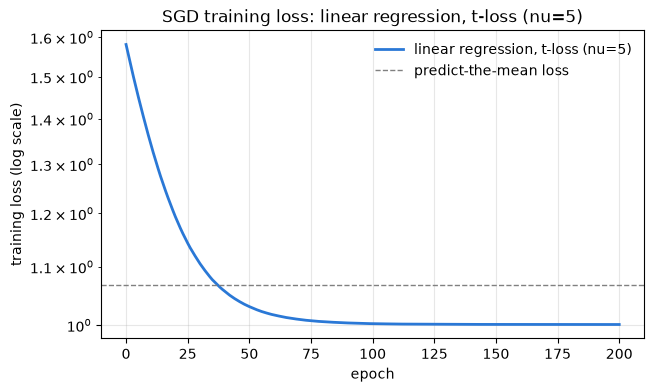

train t-loss after training: 1.00109


In [79]:
ale_t_w, ale_t_b, ale_t_loss_history = train_sgd_regression(
    predict_linear,
    "linear regression, t-loss (nu=5)",
    loss_fn=t_loss,
    learning_rate=0.01,
    batch_size=32,
    epochs=200,
    seed=0,
)
print("train t-loss after training:", round(ale_t_loss_history[-1], 5))

In [80]:
with torch.no_grad():
    ale_t_pred = predict_linear(ale_X_test_t, ale_t_w, ale_t_b).numpy()

print("t-loss SGD test MAE:", mean_absolute_error(ale_y_test, ale_t_pred))
print("MSE SGD test MAE:   ", mean_absolute_error(ale_y_test, ale_sgd_pred))
print("baseline test MAE:  ", mean_absolute_error(ale_y_test, ale_baseline_pred))
print("bias — t-loss:", round(ale_t_b.item(), 3), "| MSE SGD:", round(ale_b.item(), 3),
      "| sklearn:", round(ale_baseline.intercept_, 3))

pd.DataFrame(
    {"t-loss SGD": ale_t_w.detach().numpy(), "MSE SGD": ale_w.detach().numpy(),
     "sklearn": ale_baseline.coef_},
    index=ale_features,
).round(3)


t-loss SGD test MAE: 0.18834441779292854
MSE SGD test MAE:    0.19238619520863762
baseline test MAE:   0.1920717204588799
bias — t-loss: 1.014 | MSE SGD: 1.019 | sklearn: 1.018


,t-loss SGD,MSE SGD,sklearn
anchor_ratio,-0.053,-0.054,-0.054
trans_range,-0.068,-0.073,-0.072
node_density,-0.288,-0.294,-0.293
iterations,-0.208,-0.215,-0.214


The mean absolute errors and weights are basically the same, meaning that the outliers are not so great that the t-distribution loss function with $\nu = 5$ would do that much better than the normal distribution loss function. This implies that both represent the residual noise roughly as well as each other (as we saw in question 4, not so well). This also has to do with the parametrization of the t-distribution, perhaps a smaller $\nu$ would be better at recognizing the outliers in this dataset.